## Notebook to create a protoplanetary disk

### Initial conditions

Gas accretion onto the embryo is replaced by a subgrid model with a maximum mass limit per accretion event instead of a 0.1 AU sink

In [1]:
import numpy
from amuse.units import units, constants, nbody_system
from amuse.ext.orbital_elements import generate_binaries
from amuse.lab import Particles

In [2]:
# Generating the binary system 

M_A = 1.0788 | units.Msun
M_B = 0.9092 | units.Msun
a = 23.299 | units.au
e = 0.51947
i = 79.243 | units.deg # how it is viewed from earth, unimportant until placing a disk
long_asc_node = 205.073 | units.deg # defines how orbital plane is rotated along LoS, also unimportant
arg_per = 231.519 | units.deg # defines where periapsis lies in orbital plane, unimportant
true_an = 180 | units.deg # stars start at apastron, i.e. furthest apart
primaries, secondaries = generate_binaries(M_A, M_B, a, e, true_anomaly=true_an, G=constants.G)

alpha_cen_A = primaries[0]
alpha_cen_B = secondaries[0]

alpha_cen_A.name = "Alpha_Centauri_A"
alpha_cen_B.name = "Alpha_Centauri_B"

system = Particles()
system.add_particle(alpha_cen_A)
system.add_particle(alpha_cen_B)
system.move_to_center()

print(system)
print(alpha_cen_A.x)

                 key         mass         name           vx           vy           vz            x            y            z
                   -  1.98892e+30 * kg         none  3646245880.3572216 * m * s**-1  3646245880.3572216 * m * s**-1  3646245880.3572216 * m * s**-1  149597870691.0 * m  149597870691.0 * m  149597870691.0 * m
====================  ===========  ===========  ===========  ===========  ===========  ===========  ===========  ===========
18063231848718274796    1.079e+00  Alpha_Centauri_A    1.564e-22    6.138e-07    0.000e+00    1.619e+01   -1.983e-15   -0.000e+00
 5621059150179194206    9.092e-01  Alpha_Centauri_B   -1.856e-22   -7.283e-07    0.000e+00   -1.921e+01    2.353e-15    0.000e+00
====================  ===========  ===========  ===========  ===========  ===========  ===========  ===========  ===========
16.1909547219 149597870691.0 * m


In [3]:
# Candidate planet is a gas giant orbiting Alpha Centauri A. We can start with a fully-formed Saturn mass planet and test orbital stability. 
# After orbital stability is established (hopefully): start with a core of 10-20 Mearth and simulate core accretion of gas to form a gas giant

# First, explore orbital stability of candidate gas giant 

M_embryo = 10 | units.Mearth # increase embryo mass to see if resolution is problem
a_embryo = 2 | units.au
e_embryo = 0

stars, planets = generate_binaries(M_A, M_embryo, a_embryo, e_embryo, G=constants.G)
star = stars[0]
planet = planets[0]
planet.position -= star.position # planet position relative to star 
planet.velocity -= star.velocity # planet velocity relative to star

planet.position += system[0].position # absolute position
planet.velocity += system[0].velocity # absolute velocity 

planet.name = "Alpha_Centauri_Ab"
R_acc = 0.1 | units.au
planet.radius = R_acc

system.add_particle(planet)
system.move_to_center()
print(system)
print(alpha_cen_A.x)

                 key         mass         name       radius           vx           vy           vz            x            y            z
                   -  1.98892e+30 * kg         none           au  3646245880.3572216 * m * s**-1  3646245880.3572216 * m * s**-1  3646245880.3572216 * m * s**-1  149597870691.0 * m  149597870691.0 * m  149597870691.0 * m
====================  ===========  ===========  ===========  ===========  ===========  ===========  ===========  ===========  ===========
18063231848718274796    1.079e+00  Alpha_Centauri_A    0.000e+00    1.564e-22    6.137e-07    0.000e+00    1.619e+01   -1.983e-15   -0.000e+00
 5621059150179194206    9.092e-01  Alpha_Centauri_B    0.000e+00   -1.856e-22   -7.283e-07    0.000e+00   -1.921e+01    2.353e-15    0.000e+00
 4228168208065868505    3.003e-05  Alpha_Centauri_Ab    1.000e-01    1.564e-22    6.614e-06    0.000e+00    1.819e+01   -1.983e-15    0.000e+00
====================  ===========  ===========  ===========  =========== 

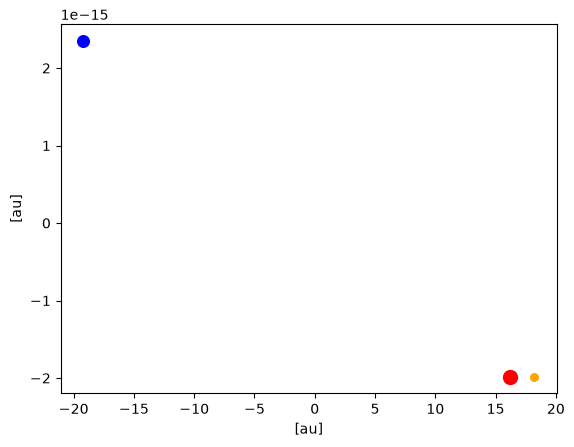

In [4]:
from amuse.plot import scatter

scatter(alpha_cen_A.x.in_(units.au), alpha_cen_A.y.in_(units.au), s=100, c='red')
scatter(alpha_cen_B.x.in_(units.au), alpha_cen_B.y.in_(units.au), s=70, c='blue')
scatter(planet.x.in_(units.au), planet.y.in_(units.au), s=30, c='orange')

In [5]:
from amuse.ext.protodisk import ProtoPlanetaryDisk

Rin = 0.2 | units.au
Rout = 3 | units.au
M_scale = M_A 
R_scale = a
converter = nbody_system.nbody_to_si(M_scale, R_scale)
Ndisk = 10000

rmin = Rin/R_scale
rmax = Rout/R_scale
Mdisk = 0.001 | units.Msun
system.move_to_center()
star_A = system[system.name == "Alpha_Centauri_A"]
disk = ProtoPlanetaryDisk(
    Ndisk,
    convert_nbody=converter,
    radius_min=rmin,
    radius_max=rmax,
    q_out=10,
    discfraction=Mdisk/M_A
).result
disk.name = "disk"

disk.move_to_center()
print(disk.position.lengths().max().in_(units.au))
disk.position += star_A.position # absolute coordinates of disk 
disk.velocity += star_A.velocity # absolute velocity of disk
masses = Mdisk / float(Ndisk) # mass distributed equally 
disk.mass = masses
rho = 3.0 | (units.g / units.cm**3) # assume density of material
disk.radius = (disk.mass / (4 * rho))**(1./3.) # assign physical radius to each particle using formula
system.add_particles(disk)

print(system)


3.01049015907 au
                 key         mass         name       radius            u           vx           vy           vz            x            y            z
                   -  1.98892e+30 * kg         none           au  m**2 * s**-2  3646245880.3572216 * m * s**-1  3646245880.3572216 * m * s**-1  3646245880.3572216 * m * s**-1  149597870691.0 * m  149597870691.0 * m  149597870691.0 * m
====================  ===========  ===========  ===========  ===========  ===========  ===========  ===========  ===========  ===========  ===========
18063231848718274796    1.079e+00  Alpha_Centauri_A    0.000e+00    0.000e+00    1.564e-22    6.137e-07    0.000e+00    1.619e+01   -1.983e-15   -0.000e+00
 5621059150179194206    9.092e-01  Alpha_Centauri_B    0.000e+00    0.000e+00   -1.856e-22   -7.283e-07    0.000e+00   -1.921e+01    2.353e-15    0.000e+00
 4228168208065868505    3.003e-05  Alpha_Centauri_Ab    1.000e-01    0.000e+00    1.564e-22    6.614e-06    0.000e+00    1.819e+01   -

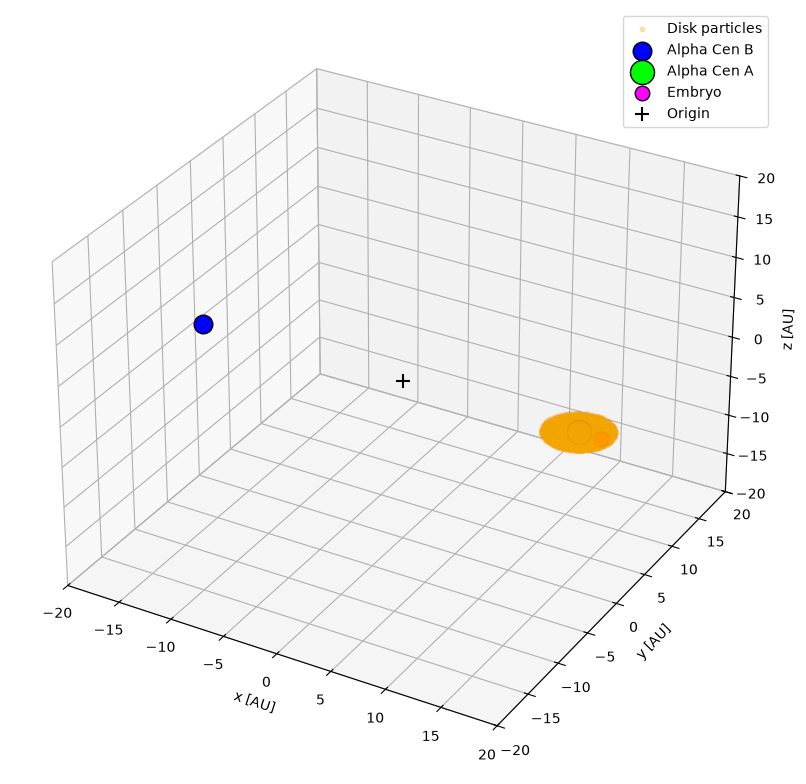

In [6]:
import matplotlib.pyplot as plt

fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(111, projection="3d")

ax.scatter(disk.x.value_in(units.au),
           disk.y.value_in(units.au),
           disk.z.value_in(units.au),
           s=10, c="orange", alpha=0.3, label="Disk particles")

ax.scatter(alpha_cen_B.x.value_in(units.au),
           alpha_cen_B.y.value_in(units.au),
           alpha_cen_B.z.value_in(units.au),
           s=180, c="blue", edgecolors="black",
           depthshade=False, label="Alpha Cen B")

ax.scatter(alpha_cen_A.x.value_in(units.au),
           alpha_cen_A.y.value_in(units.au),
           alpha_cen_A.z.value_in(units.au),
           s=300, c="lime", edgecolors="black",
           depthshade=False, label="Alpha Cen A")

ax.scatter(planet.x.value_in(units.au),
           planet.y.value_in(units.au),
           planet.z.value_in(units.au),
           s=110, c="magenta", edgecolors="black",
           depthshade=False, label="Embryo")

ax.scatter(0, 0, 0, color="black", marker="+", s=100, label="Origin")
ax.set_xlim(-20, 20)
ax.set_ylim(-20, 20)
ax.set_zlim(-20, 20)

ax.set_xlabel("x [AU]")
ax.set_ylabel("y [AU]")
ax.set_zlabel("z [AU]")
ax.legend()
plt.tight_layout()
plt.show()

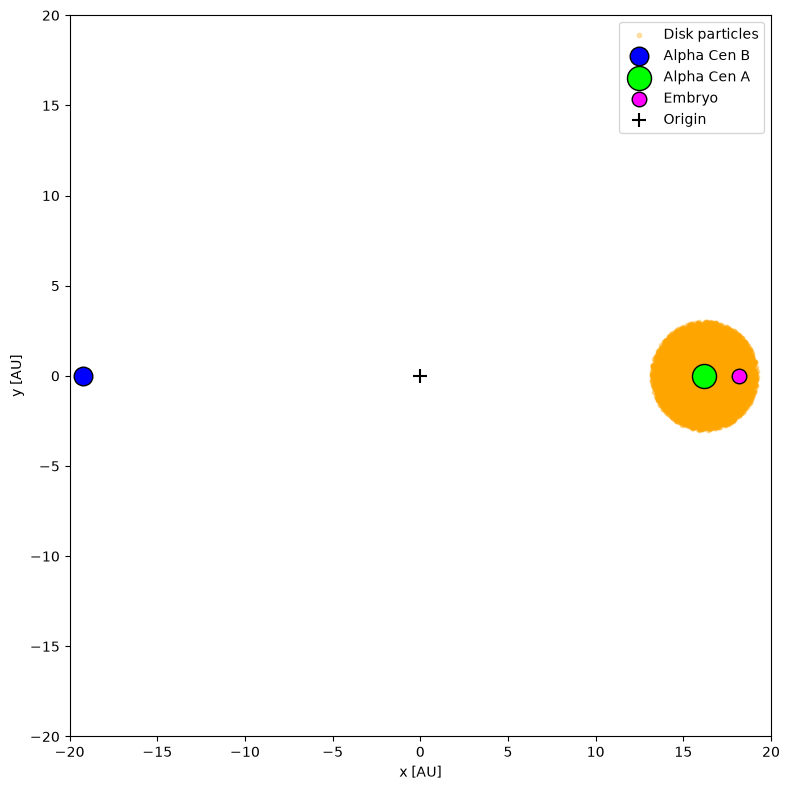

In [7]:
import matplotlib.pyplot as plt

fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot()

ax.scatter(disk.x.value_in(units.au),
           disk.y.value_in(units.au),
           s=10, c="orange", alpha=0.3, label="Disk particles")

ax.scatter(alpha_cen_B.x.value_in(units.au),
           alpha_cen_B.y.value_in(units.au),
           s=180, c="blue", edgecolors="black",
            label="Alpha Cen B")

ax.scatter(alpha_cen_A.x.value_in(units.au),
           alpha_cen_A.y.value_in(units.au),
           s=300, c="lime", edgecolors="black",
            label="Alpha Cen A")

ax.scatter(planet.x.value_in(units.au),
           planet.y.value_in(units.au),
           s=110, c="magenta", edgecolors="black",
          label="Embryo")

ax.scatter(0, 0, color="black", marker="+", s=100, label="Origin")
ax.set_xlim(-20, 20)
ax.set_ylim(-20, 20)

ax.set_xlabel("x [AU]")
ax.set_ylabel("y [AU]")
ax.legend()
plt.tight_layout()
plt.show()

## Coupled hydrodynamics + gravity

### Changes with respect to previous notebook:
- We now have star A + embryo + gas in the hydro code with star and embryo as dark matter particles
- We now compute properties of gas using the smoothing prescription of the SPH code, instead of manually smoothing over nearby particles using a Gaussian kernel. This is what SPH is designed to do no? 
- Star B is in gravity code which is updated through bridge method
- Instead of the grid-based accretion, we consider the embryo as a sink particle that accretes a gas particle when the gas particle enters its Hill radius 
- We use the sink particle module in AMUSE for the embryo. However, this module cannot be used for partial accretion (I think) because particles are always fully removed after accretion in their implementation.
- We use the Hill area gas flux to determine the accretion rate when a gas particle enters the Hill sphere 
- 10,000 SPH particles 

### Problems with this approach:
- The Hill sphere is too small to resolve for embryo mass of 0.0123 M_earth and 1000 SPH particles. Hence why I have increased to 10 M_earth as a test (but this is too large for a realistic embryo mass). This means we should either increase the number of SPH particles, increase the embryo mass (if physically plausible) or use the grid-based accretion method David developed already (since this does not require particles to be located inside the Hill sphere)
- We have to set 
```
hydro.parameters.eps_is_h_flag = False
hydro.parameters.epsilon_squared = (0.01 | units.au)**2
```
  Otherwise, the gravity of the central star gets smoothed way too much and the disk becomes unstable

### What's next?
- The approach here does not work as is because the Hill sphere is not resolved. Probably we should combine the sink particle approach with David's previous method or find a way to dramatically increase the number of SPH particles without blowing up run time.

In [8]:
# Add star A and embryo as DM particles in hydro code following comments from Simon
# Bridge only with Star B
# Embryo is now represented as a sink particle 

import numpy as np
import matplotlib.pyplot as plt
from amuse.community.huayno.interface import Huayno
from amuse.community.fi.interface import Fi
from amuse.couple.bridge import Bridge
from amuse.datamodel import Particles
from amuse.units import units, constants
from amuse.ext.sink import new_sink_particles

# Separate the initial conditions into gas, A + embryo, and B.
gas_initial = system[system.name == "disk"]
alpha_cen_A = system[system.name == "Alpha_Centauri_A"]
alpha_cen_B = system[system.name == "Alpha_Centauri_B"]
embryo_initial = system[system.name == "Alpha_Centauri_Ab"]

bodies = Particles()
bodies.add_particles(alpha_cen_A)
bodies.add_particles(embryo_initial)

assert len(bodies) == 2
assert len(gas_initial) == Ndisk
assert len(alpha_cen_B) == 1

# Record initial particle keys.
key_A = alpha_cen_A[0].key
key_B = alpha_cen_B[0].key
key_P = embryo_initial[0].key

def get_particle(particles, key):
    """Identify a particle by its stable AMUSE key."""
    matches = particles[particles.key == key]
    if len(matches) != 1:
        raise RuntimeError(f"Expected exactly one particle with key {key}, got {len(matches)}")
    return matches[0]

# Check that the gas has a physically motivated internal energy.
if 'u' not in gas_initial.get_attribute_names_defined_in_store():
    raise RuntimeError("Gas particles have no specific internal energy 'u'.")

# SPH gas-particle radii are not physical grain radii
# Fi determines the smoothing lengths
gas_initial.radius = 0 | units.au

# Alpha Centauri B is evolved by Huayno
gravity = Huayno(converter)
gravity.particles.add_particles(alpha_cen_B)

# Alpha Centauri A, the embryo and the gas are evolved by Fi
hydro = Fi(converter)
hydro.parameters.use_hydro_flag = True
hydro.parameters.timestep = 0.0002 | units.yr
hydro.parameters.gamma = 1 # isothermal eos
hydro.parameters.isothermal_flag = True # keep gas temperature constant
hydro.parameters.integrate_entropy_flag = False # dont evolve gas entropy
hydro.parameters.eps_is_h_flag = False
hydro.parameters.epsilon_squared = (0.01 | units.au)**2

hydro.dm_particles.add_particles(bodies)
hydro.gas_particles.add_particles(gas_initial)

# Create an AMUSE sink overlay for the embryo
embryo_set = hydro.dm_particles[1:2].as_set()

assert len(embryo_set) == 1

sinks = new_sink_particles(embryo_set, sink_radius=0.001 | units.au) # sink radius is placeholder, will be updated before accretion 

# Couple the Fi subsystem to Alpha Centauri B through bridge
bridge = Bridge(use_threading=False)
bridge.add_system(hydro, (gravity,))
bridge.add_system(gravity, (hydro,))
bridge.timestep = 0.002 | units.yr

# Refresh snapshots from the solver sets.
def synchronize_snapshots():
    global body_state, gas_state

    body_state = Particles()
    body_state.add_particles(hydro.dm_particles.copy())
    body_state.add_particles(gravity.particles.copy())

    gas_state = hydro.gas_particles.copy()

synchronize_snapshots()

print(hydro.dm_particles[1:2]) # indeed corresponds to embryo mass 
print('Fi DM particles:', len(hydro.dm_particles))
print('Fi gas particles:', len(hydro.gas_particles))
print('Huayno particles:', len(gravity.particles))
print('Sink particles:', len(sinks))


                 key         mass       radius           vx           vy           vz            x            y            z
                   -           kg            m    m * s**-1    m * s**-1    m * s**-1            m            m            m
====================  ===========  ===========  ===========  ===========  ===========  ===========  ===========  ===========
 4228168208065868505    5.972e+25    1.496e+09    5.703e-13    2.412e+04    0.000e+00    2.721e+12   -2.966e-04    0.000e+00
====================  ===========  ===========  ===========  ===========  ===========  ===========  ===========  ===========
Fi DM particles: 2
Fi gas particles: 10000
Huayno particles: 1
Sink particles: 1


### Obtain necessary properties to simulate accretion.

In [9]:
# printing all built-in methods
#for name in sorted(dir(hydro)):
#    if not name.startswith("_"):
#        try:
#            print(name, ":", getattr(hydro, name))
#        except Exception:
#            print(name)

In [10]:
# helper functions 

def get_local_gas_state():
    """
    Get density, velocity and internal energy density at specified position from SPH code
    """
    embryo = hydro.dm_particles[1]
    rho, rhovx, rhovy, rhovz, rhoe = hydro.get_hydro_state_at_point(embryo.x, embryo.y, embryo.z) # state at position of embryo
    v_gas = [rhovx / rho, rhovy / rho, rhovz / rho]
    v_emb = embryo.velocity
    v_rel = ((v_gas[0] - v_emb[0])**2 + (v_gas[1] - v_emb[1])**2 + (v_gas[2] - v_emb[2])**2)**0.5
    return rho, v_gas, v_rel, rhoe

def update_sink_radius():
    """
    Compute new sink radius corresponding to Hill radius based on updated positions and masses
    """
    star = hydro.dm_particles[0]
    embryo = hydro.dm_particles[1]
    r = (embryo.position - star.position).length()
    r_hill = r * (embryo.mass / (3.0 * star.mass))**(1.0 / 3.0)
    sinks[0].sink_radius = r_hill
    return r_hill

def calculate_accretion_rate(efficiency):
    """
    Hill-sphere accretion prescription:
    Mdot = efficiency * pi * R_hill^2 * rho * v_eff
    where v_eff combines embryo-gas drift and Hill shear.
    """

    star = get_particle(hydro.dm_particles, key_A)
    embryo = get_particle(hydro.dm_particles, key_P)
    rho, v_gas, v_rel, rhoe = get_local_gas_state()
    r_hill = update_sink_radius()
    r = (embryo.position - star.position).length()
    omega = (constants.G * star.mass / r**3).sqrt()
    v_hill = r_hill * omega
    v_eff = (v_rel**2 + v_hill**2).sqrt()
    mdot = efficiency * np.pi * r_hill**2 * rho * v_eff
    return mdot

def accrete_gas(dt, efficiency=0.01, max_fraction=0.01):
    embryo = hydro.dm_particles[1] # retrieve embryo 
    gas = hydro.gas_particles # retrieve gas

    if len(gas) == 0:
        return 0.0 | units.kg

    mdot = calculate_accretion_rate(efficiency) # compute accretion rate based on Hill-area gas flux
    requested_mass = mdot * dt  # mass available for accretion at this timestep
    nearby_gas = sinks.select_too_close(gas)[0] # select gas particles nearby embryo

    if len(nearby_gas) == 0:
        return 0.0 | units.kg

    available_mass = (max_fraction * nearby_gas.mass).sum() # max fraction of gas mass allowed to accrete each timestep
    transferred_mass = min(requested_mass, available_mass) 

    if transferred_mass <= 0 | units.kg:
        return 0.0 | units.kg

    r_acc = sinks[0].sink_radius
    r_i = (nearby_gas.position - embryo.position).lengths()

    weights = nearby_gas.mass * np.exp(-(r_i / r_acc)**2)
    weights /= weights.sum()

    dm = weights * transferred_mass  # amount of mass accreted from each particle   
    old_mass = embryo.mass
    new_mass = old_mass + transferred_mass
    new_momentum = (old_mass * embryo.velocity + (dm.reshape((len(dm), 1)) * nearby_gas.velocity).sum(axis=0)) # p_old + delta_m*delta_v
    embryo.mass = new_mass
    embryo.velocity = new_momentum / new_mass
    nearby_gas.mass -= dm

    return transferred_mass

In [11]:
# Disk morphology and stability diagnostics (restored).
def disk_metrics():
    synchronize_snapshots()
    A = get_particle(body_state, key_A)
    P = get_particle(body_state, key_P)
    if len(gas_state) == 0:
        return dict(mdisk=0., r10=np.nan, r50=np.nan, r90=np.nan,
                    near_planet=0, x=np.array([]), y=np.array([]))
    r = (gas_state.position - A.position).lengths().value_in(units.au)
    order = np.argsort(r)
    mass = gas_state.mass.value_in(units.Msun)
    cdf = np.cumsum(mass[order]) / mass.sum()
    q = np.interp([0.1, 0.5, 0.9], cdf, r[order])
    dist_planet = (gas_state.position - P.position).lengths().value_in(units.au)
    return dict(mdisk=float(mass.sum()), r10=q[0], r50=q[1], r90=q[2],
                near_planet=int(np.sum(dist_planet < 0.2)),
                x=(gas_state.x-A.x).value_in(units.au).copy(),
                y=(gas_state.y-A.y).value_in(units.au).copy())


# Bound-gas and morphology diagnostics relative to Alpha Centauri A.
# A two-body binding proxy is used here; companion tides and pressure can
# exchange energy, so instantaneous bound fraction is NOT a permanent survival test.
def disk_stability_metrics():
    A = hydro.dm_particles[0]
    B = gravity.particles[0]
    embryo = hydro.dm_particles[1]
    gas = hydro.gas_particles.copy()
    if len(gas) == 0:
        return dict(bound_fraction=np.nan, r90_bound=np.nan, disk_eccentricity=np.nan)
    dr = gas.position - A.position
    dv = gas.velocity - A.velocity
    r = dr.lengths()
    eps = 0.5 * dv.lengths_squared() - constants.G * A.mass / r
    bound = gas[eps < (0 | (units.m**2 / units.s**2))]
    frac = float(bound.total_mass() / gas.total_mass()) if len(bound) else 0.0
    if not len(bound):
        return dict(bound_fraction=float(frac), r90_bound=np.nan, disk_eccentricity=np.nan)
    rb = (bound.position - A.position).lengths().value_in(units.au)
    mb = bound.mass.value_in(units.Msun)
    inds = np.argsort(rb)
    cdf = np.cumsum(mb[inds]) / np.sum(mb)
    r90_bound = float(np.interp(0.9, cdf, rb[inds]))
    # Mass-weighted instantaneous osculating eccentricity (Kepler proxy).
    d = (bound.position - A.position).value_in(units.m)
    v = (bound.velocity - A.velocity).value_in(units.m / units.s)
    mu = (constants.G * A.mass).value_in(units.m**3 / units.s**2)
    h = np.cross(d, v)
    evec = np.cross(v, h) / mu - d / np.linalg.norm(d, axis=1)[:, None]
    eccentricity = float(np.average(np.linalg.norm(evec, axis=1), weights=mb))
    return dict(bound_fraction=float(frac), r90_bound=r90_bound, disk_eccentricity=eccentricity)


In [12]:
# Accretion diagnostics 

def accretion_step(dt, efficiency=0.01, max_fraction=0.01):
    # Update the sink radius and obtain local gas properties.
    hill = update_sink_radius()
    rho, v_gas, v_rel, rhoe = get_local_gas_state()

    # Record the potential donor particles before accretion.
    nearby_gas = sinks.select_too_close(hydro.gas_particles)[0]
    mass_before = np.array([
    m.value_in(units.kg) for m in nearby_gas.mass
])

    dm = accrete_gas(dt, efficiency=efficiency, max_fraction=max_fraction)

    mass_after = np.array([
    m.value_in(units.kg) for m in nearby_gas.mass
])

    dm_particles = mass_before - mass_after
    n_affected = np.count_nonzero(dm_particles > 0.0)

    return dict(
        dm=dm.value_in(units.MEarth),
        n_affected=n_affected,
        hill_au=hill.value_in(units.au),
        kernel_au=np.nan,
        rho_kg_m3=rho.value_in(units.kg / units.m**3)
    )

In [13]:
update_sink_radius()
r_acc = sinks[0].sink_radius

h_min = hydro.gas_particles.h_smooth.min()
h_mean = hydro.gas_particles.h_smooth.mean()
h_max = hydro.gas_particles.h_smooth.max()

print("R_acc  =", r_acc.in_(units.au))
print("h_min  =", h_min.in_(units.au))
print("h_mean =", h_mean.in_(units.au))
print("h_max  =", h_max.in_(units.au))

R_acc  = 0.0420256985413 au
h_min  = 0.0193452252447 au
h_mean = 0.0796584686999 au
h_max  = 0.225859797558 au


In [14]:
# One-year pilot.
t_start = bridge.model_time
t_end = t_start + 1.0 | units.yr
output_dt = 0.02 | units.yr
n_outputs = int(round((t_end - t_start) / output_dt))

history = []
accreted_mass_total = 0.0 | units.MEarth


def save_record(t, acc=None):
    if acc is None:
        acc = dict(
            dm=0.0,
            n_affected=0,
            hill_au=np.nan,
            kernel_au=np.nan,
            rho_kg_m3=np.nan
        )

    m = disk_metrics()

    # Current particle ordering: A at index 0, embryo at index 1.
    embryo = hydro.dm_particles[1]

    history.append(dict(
        t=(t - t_start).value_in(units.yr),
        embryo_mass=embryo.mass.value_in(units.MEarth),
        n_gas=len(gas_state),
        n_accreted=acc['n_affected'],
        dm_accreted=acc['dm'],
        hill_au=acc['hill_au'],
        kernel_au=acc['kernel_au'],
        rho_kg_m3=acc['rho_kg_m3'],
        **m,
        **disk_stability_metrics()
    ))


# Initial record.
synchronize_snapshots()
save_record(t_start)

for j in range(1, n_outputs + 1):

    target = t_start + j * output_dt

    # Evolve Fi and Huayno through Bridge.
    bridge.evolve_model(target)

    # Accrete gas after each output interval.
    acc = accretion_step(
        output_dt,
        efficiency=0.01,
        max_fraction=0.01
    )

    accreted_mass_total += acc['dm'] | units.MEarth

    # Refresh snapshots after evolution and accretion.
    synchronize_snapshots()

    save_record(target, acc)

    h = history[-1]

    print(
        f"t={h['t']:.3f} yr, "
        f"gas={h['n_gas']}, "
        f"embryo={h['embryo_mass']:.6g} Mearth, "
        f"dm={acc['dm']:.3e} Mearth, "
        f"donors={acc['n_affected']}, "
        f"Hill={acc['hill_au']:.3e} AU, "
        f"rho={acc['rho_kg_m3']:.3e} kg/m^3",
        flush=True
    )

print(
    "Total transferred gas mass:",
    f"{accreted_mass_total.value_in(units.MEarth):.6e} Mearth"
)


t=0.020 yr, gas=10000, embryo=10 Mearth, dm=1.741e-05 Mearth, donors=3, Hill=4.203e-02 AU, rho=2.446e-07 kg/m^3
t=0.040 yr, gas=10000, embryo=10 Mearth, dm=1.727e-05 Mearth, donors=3, Hill=4.203e-02 AU, rho=2.399e-07 kg/m^3
t=0.060 yr, gas=10000, embryo=10.0001 Mearth, dm=1.719e-05 Mearth, donors=3, Hill=4.203e-02 AU, rho=2.361e-07 kg/m^3
t=0.080 yr, gas=10000, embryo=10.0001 Mearth, dm=1.715e-05 Mearth, donors=3, Hill=4.203e-02 AU, rho=2.328e-07 kg/m^3
t=0.100 yr, gas=10000, embryo=10.0001 Mearth, dm=1.715e-05 Mearth, donors=3, Hill=4.203e-02 AU, rho=2.303e-07 kg/m^3
t=0.120 yr, gas=10000, embryo=10.0001 Mearth, dm=1.721e-05 Mearth, donors=4, Hill=4.203e-02 AU, rho=2.285e-07 kg/m^3
t=0.140 yr, gas=10000, embryo=10.0001 Mearth, dm=1.731e-05 Mearth, donors=4, Hill=4.202e-02 AU, rho=2.273e-07 kg/m^3
t=0.160 yr, gas=10000, embryo=10.0001 Mearth, dm=1.747e-05 Mearth, donors=4, Hill=4.202e-02 AU, rho=2.267e-07 kg/m^3
t=0.180 yr, gas=10000, embryo=10.0002 Mearth, dm=1.769e-05 Mearth, donors=

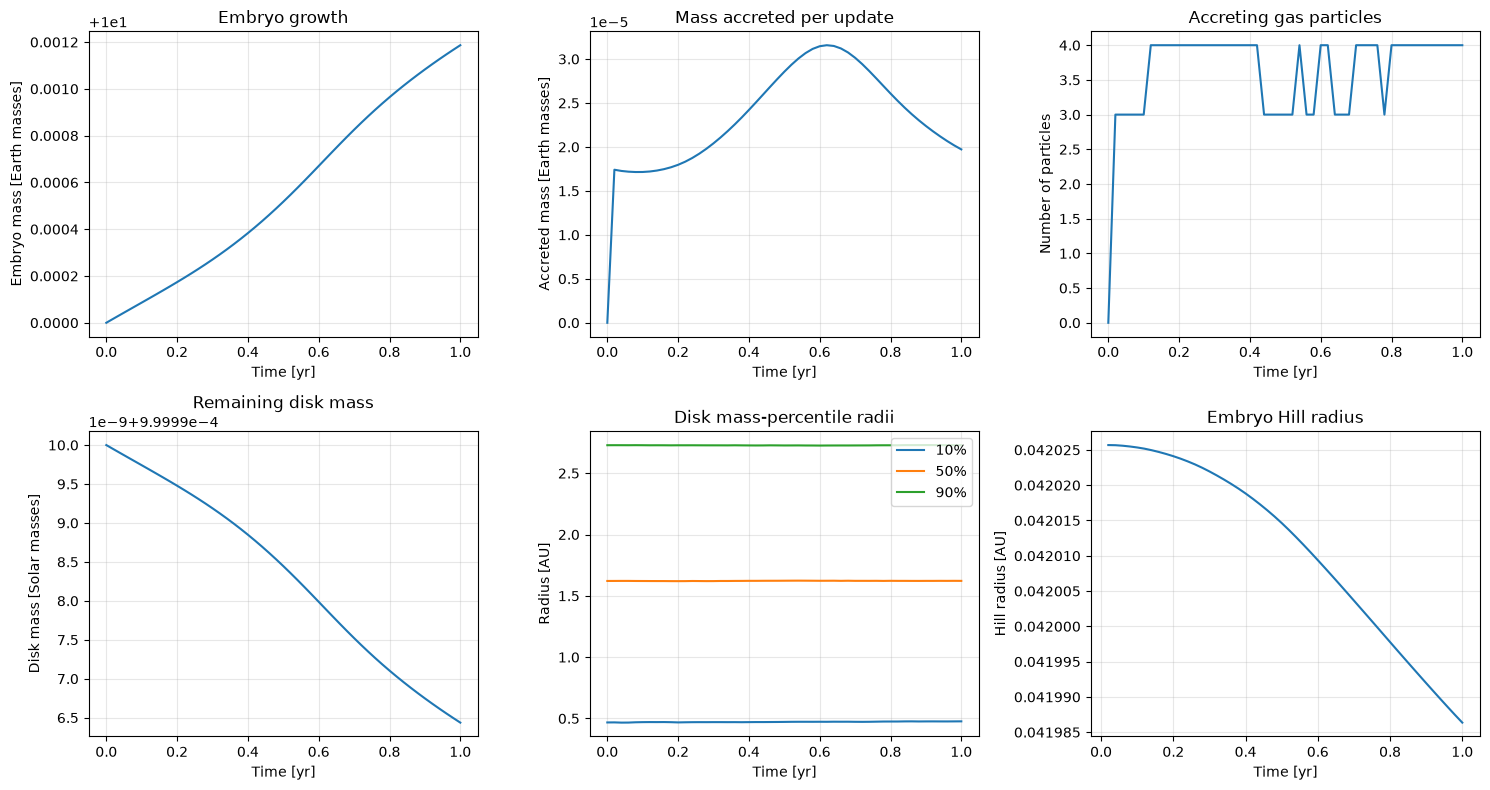

In [15]:
import numpy as np
import matplotlib.pyplot as plt

t = np.array([h['t'] for h in history])

# Accretion diagnostics
embryo_mass = np.array([h['embryo_mass'] for h in history])
dm_accreted = np.array([h['dm_accreted'] for h in history])
n_accreted = np.array([h['n_accreted'] for h in history])
hill = np.array([h['hill_au'] for h in history])
rho = np.array([h['rho_kg_m3'] for h in history])

# Disk diagnostics
mdisk = np.array([h['mdisk'] for h in history])
r10 = np.array([h['r10'] for h in history])
r50 = np.array([h['r50'] for h in history])
r90 = np.array([h['r90'] for h in history])

fig, axes = plt.subplots(2, 3, figsize=(15, 8))

# Embryo mass
axes[0, 0].plot(t, embryo_mass)
axes[0, 0].set(xlabel='Time [yr]', ylabel='Embryo mass [Earth masses]',
               title='Embryo growth')

# Accreted mass per update
axes[0, 1].plot(t, dm_accreted)
axes[0, 1].set(xlabel='Time [yr]', ylabel='Accreted mass [Earth masses]',
               title='Mass accreted per update')

# Number of affected gas particles
axes[0, 2].plot(t, n_accreted)
axes[0, 2].set(xlabel='Time [yr]', ylabel='Number of particles',
               title='Accreting gas particles')

# Remaining disk mass
axes[1, 0].plot(t, mdisk)
axes[1, 0].set(xlabel='Time [yr]', ylabel='Disk mass [Solar masses]',
               title='Remaining disk mass')

# Disk radial evolution
axes[1, 1].plot(t, r10, label='10%')
axes[1, 1].plot(t, r50, label='50%')
axes[1, 1].plot(t, r90, label='90%')
axes[1, 1].set(xlabel='Time [yr]', ylabel='Radius [AU]',
               title='Disk mass-percentile radii')
axes[1, 1].legend()

# Hill radius
axes[1, 2].plot(t, hill)
axes[1, 2].set(xlabel='Time [yr]', ylabel='Hill radius [AU]',
               title='Embryo Hill radius')

for ax in axes.flat:
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


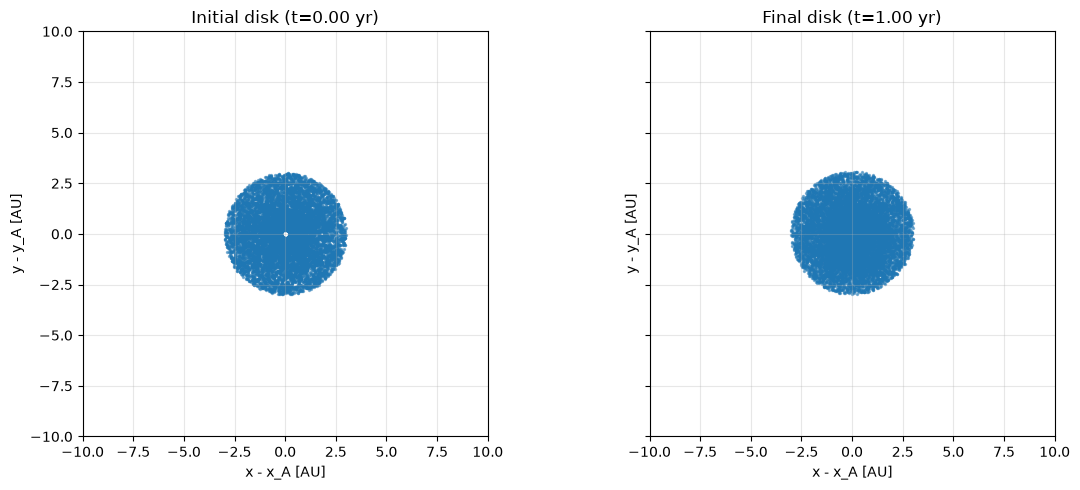

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)

for ax, h, title in zip(
    axes,
    [history[0], history[-1]],
    ['Initial disk', 'Final disk']
):
    ax.scatter(h['x'], h['y'], s=2, alpha=0.5)
    ax.set(
        xlabel='x - x_A [AU]',
        ylabel='y - y_A [AU]',
        title=f"{title} (t={h['t']:.2f} yr)"
    )
    ax.set_aspect('equal')
    ax.set_xlim(-10, 10)
    ax.set_ylim(-10, 10)
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

###  Test with Alpha Cent. A + disk to see why disk is unstable

Turns out we should set:  
hydro_test.parameters.eps_is_h_flag = False  
hydro_test.parameters.epsilon_squared = (0.01 | units.au)**2  
Otherwise the gravity of the star is smoothed enormously! 

In [48]:
from amuse.community.fi.interface import Fi
from amuse.units import units
import numpy as np
import matplotlib.pyplot as plt

# Use fresh copies of the original initial conditions.
gas_test = system[system.name == "disk"].copy()
star_test = system[system.name == "Alpha_Centauri_A"].copy()

assert len(gas_test) == Ndisk
assert len(star_test) == 1

# Set SPH particle radii to zero.
gas_test.radius = 0 | units.au

# Initialise Fi.
hydro_test = Fi(converter)

# Thermodynamics: isothermal equation of state.
hydro_test.parameters.gamma = 1 # isothermal eos
hydro_test.parameters.isothermal_flag = True # keep gas temperature constant
hydro_test.parameters.integrate_entropy_flag = False # dont evolve gas entropy

hydro_test.parameters.eps_is_h_flag = False
hydro_test.parameters.epsilon_squared = (0.01 | units.au)**2


hydro_test.parameters.timestep = 0.0002 | units.yr

print(gas_test.velocity.lengths().min().in_(units.kms))
print(gas_test.velocity.lengths().max().in_(units.kms))

# Add Alpha Cen A and the gas disk.
hydro_test.dm_particles.add_particles(star_test)
hydro_test.gas_particles.add_particles(gas_test)

print(hydro_test.gas_particles.velocity.lengths().mean())

15.6716884091 kms
69.855460358 kms
28416.8349995 m * s**-1


In [49]:
print(star_test.mass)
print(hydro_test.dm_particles.mass)
print(converter)

[1.0788] 1.98892e+30 * kg
[2.145646896e+30] kg


In [50]:
from amuse.units import constants

r = hydro_test.gas_particles.position.lengths()

v_expected = (constants.G * hydro_test.dm_particles[0].mass / r).sqrt()

print(v_expected.min().in_(units.kms))
print(v_expected.max().in_(units.kms))

7.07802583902 kms
8.50887392814 kms


In [51]:
def get_disk_state():
    gas = hydro_test.gas_particles
    star = hydro_test.dm_particles[0]

    relative_position = gas.position - star.position
    radius = relative_position.lengths()

    return {
        "mass": gas.mass.sum().value_in(units.MSun),
        "r10": np.percentile(radius.value_in(units.au), 10),
        "r50": np.percentile(radius.value_in(units.au), 50),
        "r90": np.percentile(radius.value_in(units.au), 90),
        "x": relative_position.x.value_in(units.au),
        "y": relative_position.y.value_in(units.au)
    }

history_disk = []

def save_disk_state():
    state = get_disk_state()
    state["t"] = hydro_test.model_time.value_in(units.yr)
    print(f"Time: {state['t']} yr")
    history_disk.append(state)

save_disk_state()

Time: 0.0 yr


In [52]:
t_end = 1.0 | units.yr
output_dt = 0.02 | units.yr
model_time = 0.0 | units.yr

while model_time < t_end:
    model_time += output_dt
    hydro_test.evolve_model(model_time)    
    save_disk_state()

print("Simulation finished.")

Time: 0.020000000000000025 yr
Time: 0.04000000000000049 yr
Time: 0.05999999999999844 yr
Time: 0.07999999999999294 yr
Time: 0.09999999999998743 yr
Time: 0.1199999999999819 yr
Time: 0.13999999999998214 yr
Time: 0.15999999999998232 yr
Time: 0.18000000000000071 yr
Time: 0.20000000000001913 yr
Time: 0.22000000000003753 yr
Time: 0.24000000000005592 yr
Time: 0.26000000000007434 yr
Time: 0.28000000000009273 yr
Time: 0.3000000000001111 yr
Time: 0.3200000000001295 yr
Time: 0.34000000000014796 yr
Time: 0.3600000000001663 yr
Time: 0.38000000000018475 yr
Time: 0.4000000000002031 yr
Time: 0.42000000000022153 yr
Time: 0.4400000000002399 yr
Time: 0.4600000000002583 yr
Time: 0.4800000000002767 yr
Time: 0.5000000000002951 yr
Time: 0.5200000000003134 yr
Time: 0.5400000000003247 yr
Time: 0.5600000000002474 yr
Time: 0.5800000000001981 yr
Time: 0.6000000000001209 yr
Time: 0.6200000000000436 yr
Time: 0.6399999999999664 yr
Time: 0.6599999999998891 yr
Time: 0.6799999999998119 yr
Time: 0.6999999999997346 yr
Tim

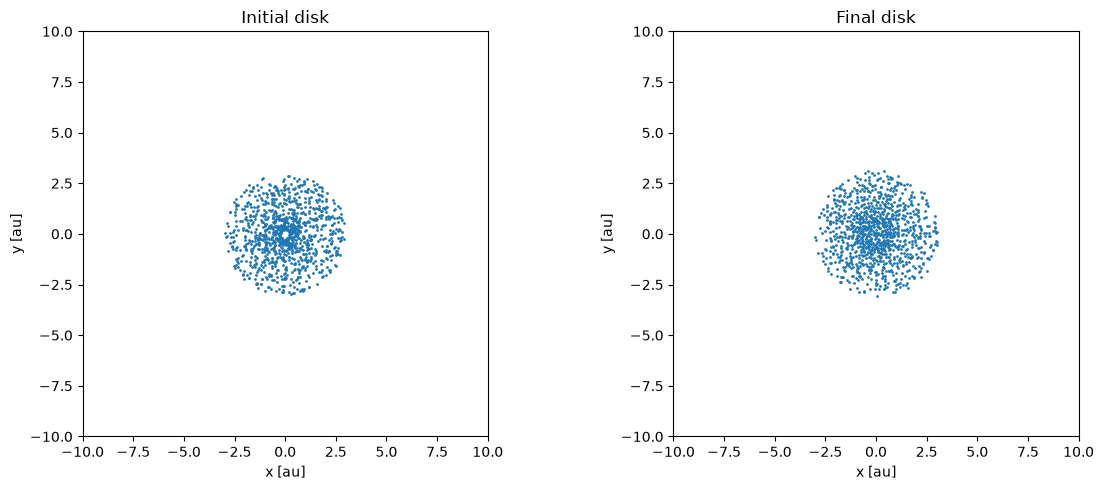

In [53]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, index, title in zip(
    axes,
    [0, -1],
    ["Initial disk", "Final disk"]
):
    state = history_disk[index]
    ax.scatter(state["x"], state["y"], s=1)
    ax.set_xlabel("x [au]")
    ax.set_ylabel("y [au]")
    ax.set_title(title)
    ax.set_aspect("equal")
    ax.set_xlim(-10, 10)
    ax.set_ylim(-10, 10)

plt.tight_layout()
plt.show()

(-3.2510148222446751,
 3.2748116117286976,
 -3.2545249013617163,
 3.2416087148616723)

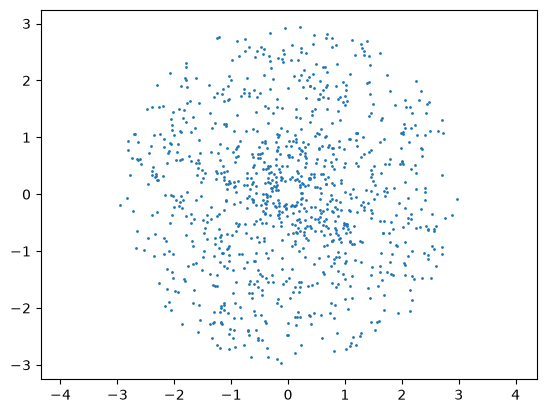

In [38]:
star = hydro_test.dm_particles[0]
gas = hydro_test.gas_particles

plt.figure()
plt.scatter(
    (gas.x - star.x).value_in(units.au),
    (gas.y - star.y).value_in(units.au),
    s=1
)
plt.axis("equal")

In [39]:
print("K =", hydro_test.kinetic_energy)
print("U =", hydro_test.potential_energy)
print("2K/|U| =", 2*hydro_test.kinetic_energy/abs(hydro_test.potential_energy))


K = 6.25709649183e+36 m**2 * kg * s**-2
U = -2.24308468522e+35 m**2 * kg * s**-2
2K/|U| = 55.790104877


In [40]:
print(hydro_test.parameters.eps_is_h_flag)
print(hydro_test.parameters.epsilon_squared)

True
1.21485763321e+25 m**2
